# fotoapp_testdev — Pruebas del módulo `fotoapp.py`

Proyecto 2 - Programación Python Avanzada (UPSO, 2026)

En este notebook **probamos cada función** del módulo `fotoapp.py`, cada una con una foto distinta, como pide la consigna.
Todas las figuras se guardan en la carpeta `resultados/`.

> Para que funcione, este notebook tiene que estar **en la misma carpeta** que `fotoapp.py`.

## 0. Preparación

In [1]:

import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from skimage import data

import fotoapp          # nuestro módulo: el archivo fotoapp.py

%matplotlib inline
plt.rcParams["figure.dpi"] = 72    # figuras más livianas dentro del notebook

### Fotos de prueba

Usamos imágenes de ejemplo que vienen con scikit-image y las guardamos en la carpeta `imagenes/`.
Como no teníamos una foto oscura ni una sobreexpuesta reales, las **simulamos**:

- **oscura**: multiplicamos los píxeles por 0.3 (todo queda entre 0 y 76).
- **sobreexpuesta**: multiplicamos por 0.35 y sumamos 165 (todo queda entre 165 y 254: muy clara y con poco contraste).

Si la carpeta ya tiene las fotos, no se vuelven a crear (así se pueden reemplazar por fotos propias con el mismo nombre).

In [2]:
os.makedirs("imagenes", exist_ok=True)

fotos = {
    "imagenes/cohete.jpg": data.rocket(),
    "imagenes/astronauta.jpg": data.astronaut(),
    "imagenes/camarografo.png": data.camera(),
    "imagenes/foto_oscura.jpg": (data.coffee() * 0.3).astype(np.uint8),
    "imagenes/foto_sobreexpuesta.jpg": (data.chelsea() * 0.35 + 165).astype(np.uint8),
}

for ruta, arreglo in fotos.items():
    if not os.path.exists(ruta):
        Image.fromarray(arreglo).save(ruta)
    print(ruta, "->", Image.open(ruta).size)

imagenes/cohete.jpg -> (640, 427)
imagenes/astronauta.jpg -> (512, 512)
imagenes/camarografo.png -> (512, 512)
imagenes/foto_oscura.jpg -> (600, 400)
imagenes/foto_sobreexpuesta.jpg -> (451, 300)


## 1. Abrir y redimensionar para cada red social

| Red social | Tamaño (ancho x alto) | Proporción |
|---|---|---|
| Youtube | 1280 x 720 | 16:9 |
| Instagram | 1080 x 1080 | 1:1 |
| Twitter | 1600 x 900 | 16:9 |
| Facebook | 1200 x 630 | 1.91:1 |

Usamos `ImageOps.fit`: la foto **no se deforma**, se escala y se recorta lo que sobra desde el centro.
Primero comparamos con un `resize` común para ver la diferencia.

Original: (640, 427) -> Instagram: (1080, 1080)


Figura guardada en: resultados/1_resize_vs_fit.png


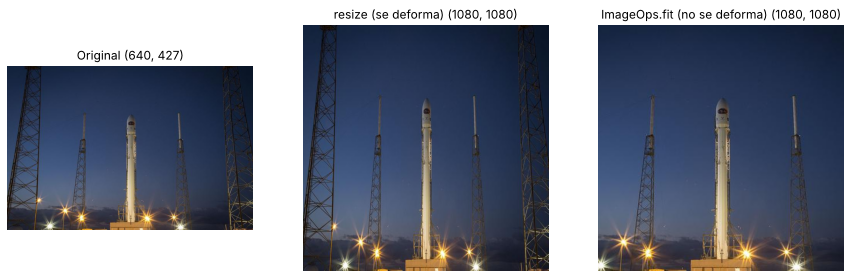

In [ ]:
original = Image.open("imagenes/cohete.jpg")
deformada = original.resize((1080, 1080))                     # resize común: estira la imagen
bien = fotoapp.redimensionar_para_red("imagenes/cohete.jpg", "Instagram")

plt.figure(figsize=(15, 5))
for i, (img, titulo) in enumerate([(original, "Original"), (deformada, "resize (se deforma)"),
                                   (bien, "ImageOps.fit (no se deforma)")]):
    plt.subplot(1, 3, i + 1)
    plt.imshow(img)
    plt.title(f"{titulo} {img.size}")
    plt.axis("off")
fotoapp.guardar_figura("1_resize_vs_fit.png")
plt.show()

Original: (640, 427) -> Youtube: (1280, 720)
Original: (640, 427) -> Instagram: (1080, 1080)
Original: (640, 427) -> Twitter: (1600, 900)
Original: (640, 427) -> Facebook: (1200, 630)


Figura guardada en: resultados/1_redes_sociales.png


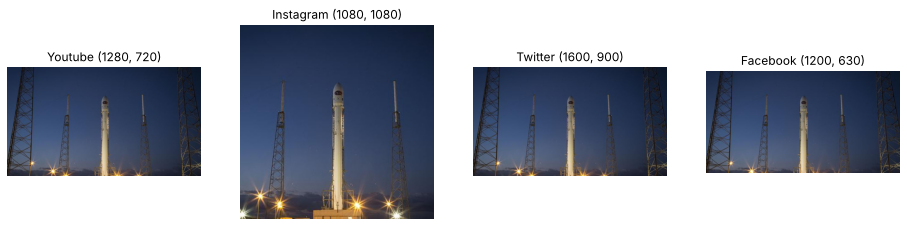

In [ ]:
redes = ["Youtube", "Instagram", "Twitter", "Facebook"]

plt.figure(figsize=(16, 4))
for i, red in enumerate(redes):
    img = fotoapp.redimensionar_para_red("imagenes/cohete.jpg", red)
    plt.subplot(1, 4, i + 1)
    plt.imshow(img)
    plt.title(f"{red} {img.size}")
    plt.axis("off")
fotoapp.guardar_figura("1_redes_sociales.png")
plt.show()

También funciona con una **URL** (necesita internet):

Original: (512, 480) -> Facebook: (1200, 630)


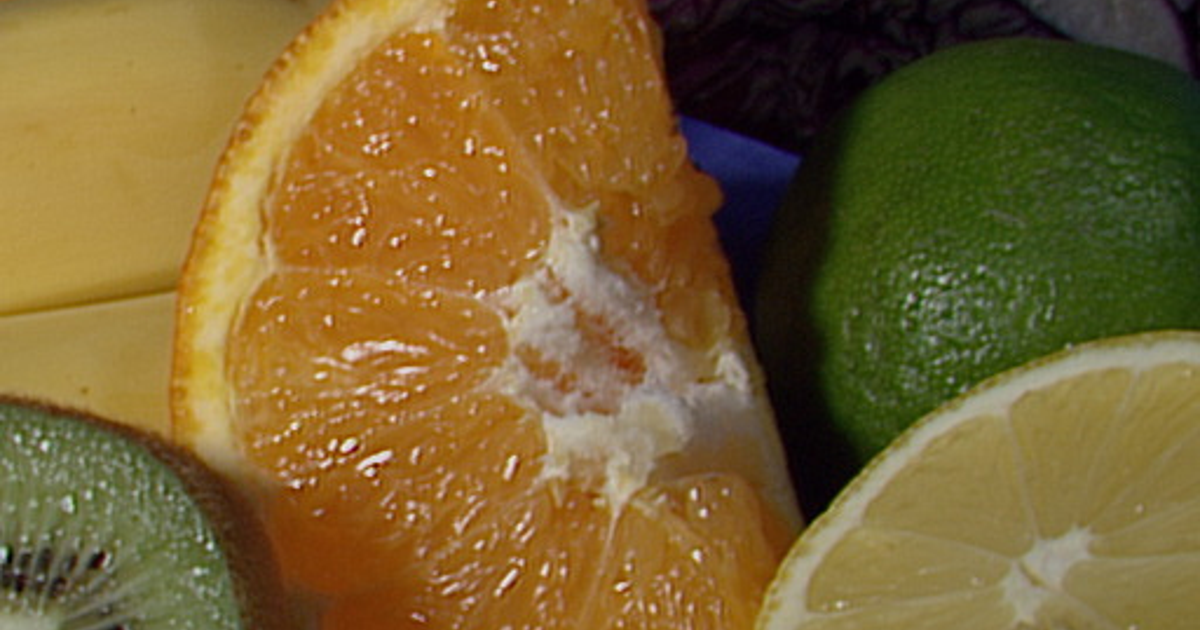

In [ ]:
url = "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/fruits.jpg"
frutas = fotoapp.redimensionar_para_red(url, "Facebook")
frutas

Probamos que las **excepciones** funcionen con datos incorrectos:

In [ ]:
try:
    fotoapp.redimensionar_para_red("imagenes/cohete.jpg", "TikTok")
except ValueError as error:
    print("ValueError:", error)

try:
    fotoapp.redimensionar_para_red("imagenes/no_existe.jpg", "Instagram")
except FileNotFoundError as error:
    print("FileNotFoundError:", error)

try:
    fotoapp.ecualizar_histograma(None)        # intentar editar sin haber cargado una imagen
except fotoapp.ImagenNoCargadaError as error:
    print("ImagenNoCargadaError:", error)

ValueError: Red social 'TikTok' no válida. Opciones: Youtube, Instagram, Twitter, Facebook.
FileNotFoundError: No se encontró el archivo: imagenes/no_existe.jpg
ImagenNoCargadaError: Todavía no cargaste ninguna imagen. Primero usá la opción 1 del menú.


## 2. Ajustar el contraste con el histograma

Se ecualiza solo el canal **V (brillo)** del espacio HSV, así los colores no cambian.
Probamos con una foto **oscura** y con una **sobreexpuesta**.

Original: (600, 400) -> Facebook: (1200, 630)


Figura guardada en: resultados/2_ecualizacion_oscura.png


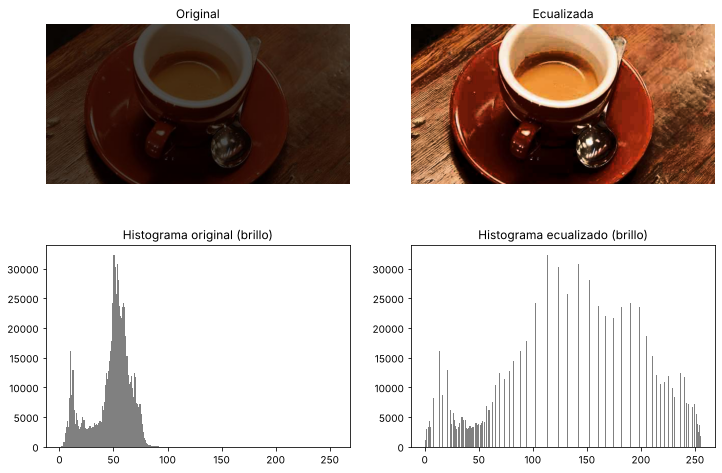

In [ ]:
oscura = fotoapp.redimensionar_para_red("imagenes/foto_oscura.jpg", "Facebook")
oscura_eq = fotoapp.ecualizar_histograma(oscura, "2_ecualizacion_oscura.png")

**Oscura:** el histograma original está todo amontonado a la izquierda (valores bajos). Después de ecualizar ocupa todo el rango de 0 a 255.

Original: (451, 300) -> Twitter: (1600, 900)


Figura guardada en: resultados/2_ecualizacion_sobreexpuesta.png


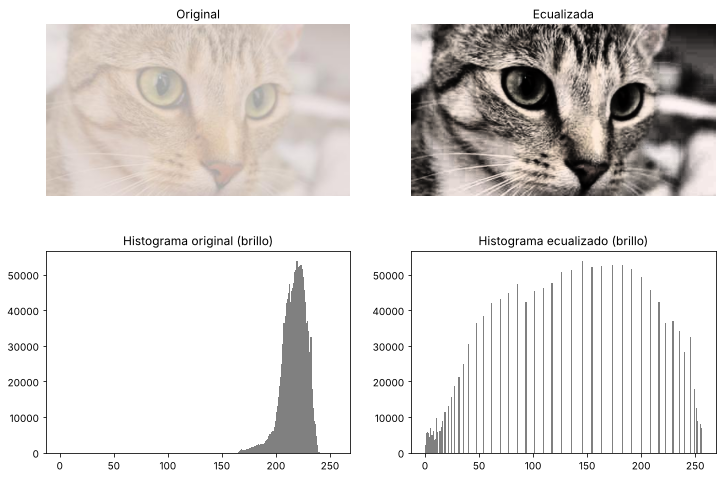

In [ ]:
clara = fotoapp.redimensionar_para_red("imagenes/foto_sobreexpuesta.jpg", "Twitter")
clara_eq = fotoapp.ecualizar_histograma(clara, "2_ecualizacion_sobreexpuesta.png")

**Sobreexpuesta:** el histograma original está amontonado a la derecha y es angosto (poco contraste). Al ecualizar se estira y aparecen las sombras y los detalles.

## 3. Los 9 filtros de Pillow

Aplicamos los 9 filtros sobre la misma foto. Cada llamada muestra la original y la filtrada y guarda la figura.

Original: (512, 512) -> Instagram: (1080, 1080)


Figura guardada en: resultados/3_filtro_blur.png


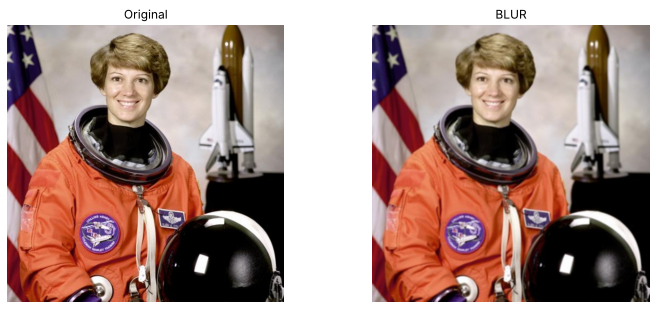

Figura guardada en: resultados/3_filtro_contour.png


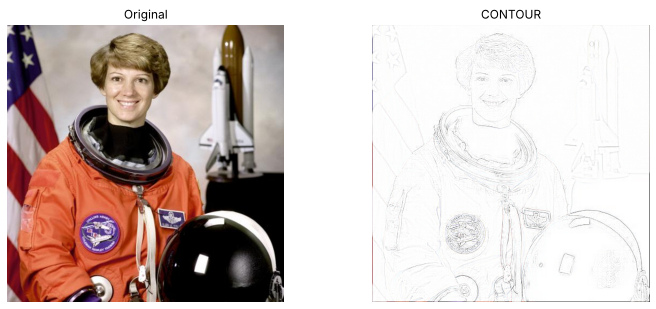

Figura guardada en: resultados/3_filtro_detail.png


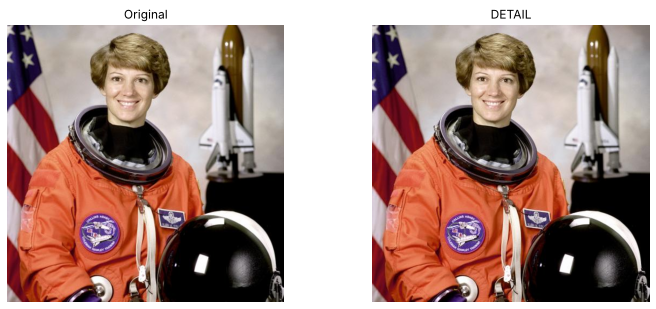

Figura guardada en: resultados/3_filtro_edge_enhance.png


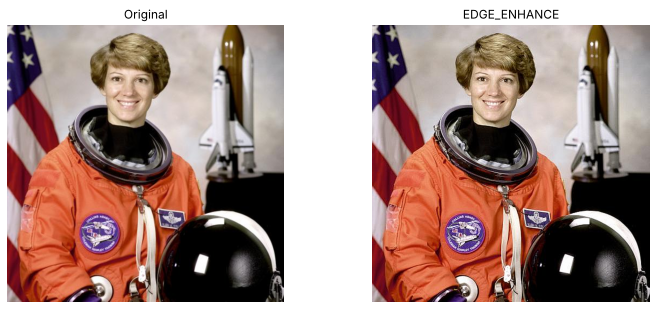

Figura guardada en: resultados/3_filtro_edge_enhance_more.png


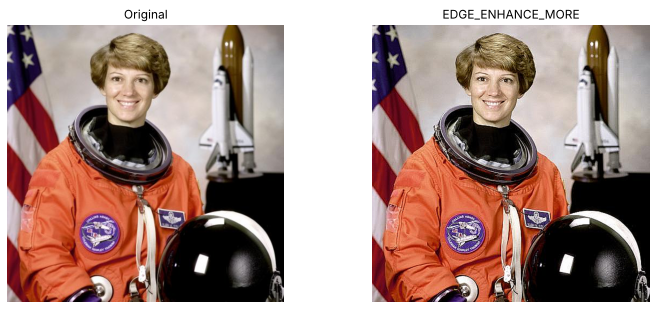

Figura guardada en: resultados/3_filtro_emboss.png


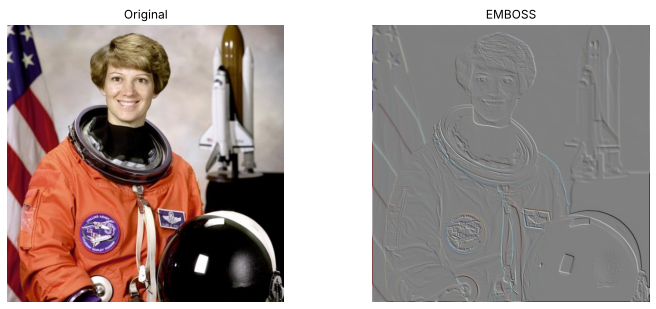

Figura guardada en: resultados/3_filtro_find_edges.png


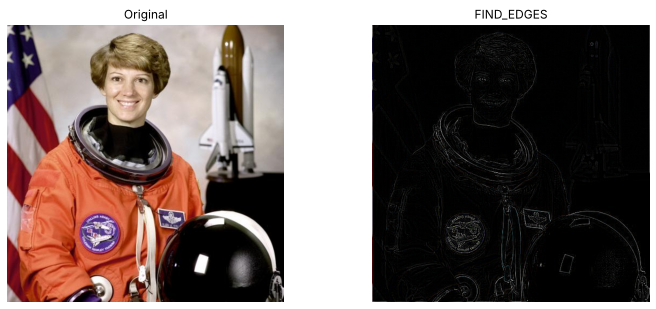

Figura guardada en: resultados/3_filtro_sharpen.png


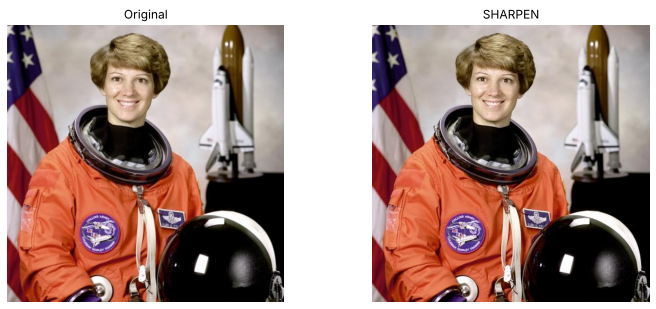

Figura guardada en: resultados/3_filtro_smooth.png


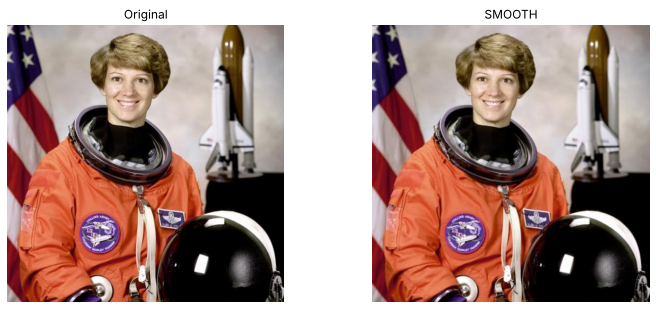

In [ ]:
astronauta = fotoapp.redimensionar_para_red("imagenes/astronauta.jpg", "Instagram")

filtradas = {}
for nombre in fotoapp.LISTA_FILTROS:
    filtradas[nombre] = fotoapp.aplicar_filtro(astronauta, nombre, f"3_filtro_{nombre.lower()}.png")

Para **comparar** los resultados, ponemos los 9 juntos en una grilla de 3x3 (hacemos zoom en la cara para que se noten las diferencias):

Figura guardada en: resultados/3_comparacion_filtros.png


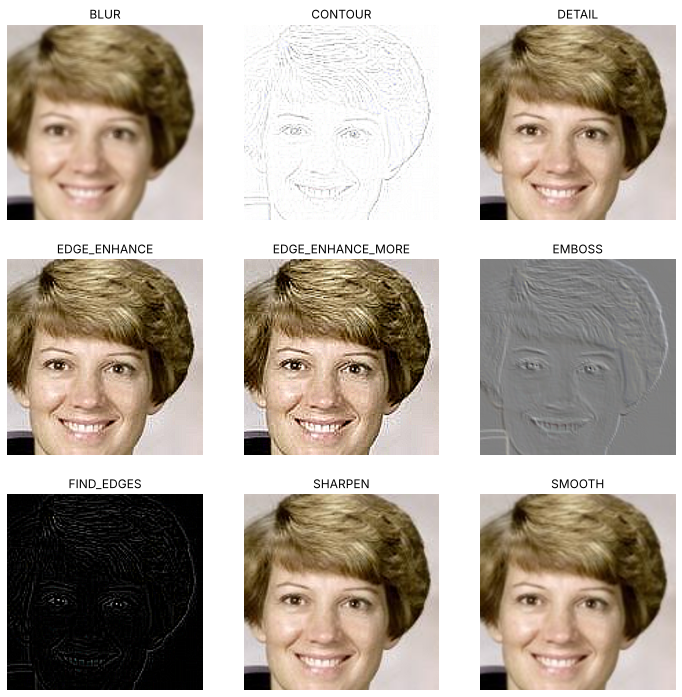

In [ ]:
plt.figure(figsize=(12, 12))
for i, (nombre, img) in enumerate(filtradas.items()):
    plt.subplot(3, 3, i + 1)
    plt.imshow(img.crop((350, 50, 650, 350)))        # zoom en la cara
    plt.title(nombre)
    plt.axis("off")
fotoapp.guardar_figura("3_comparacion_filtros.png")
plt.show()

**Comparación:**

- **BLUR** y **SMOOTH** suavizan (promedian vecinos). BLUR es mucho más fuerte; SMOOTH apenas se nota.
- **SHARPEN**, **DETAIL**, **EDGE_ENHANCE** y **EDGE_ENHANCE_MORE** hacen lo contrario: realzan los cambios, la foto se ve más nítida. EDGE_ENHANCE_MORE es el más exagerado.
- **FIND_EDGES** deja solo los bordes sobre fondo negro, y **CONTOUR** hace lo mismo pero con líneas oscuras sobre fondo blanco (como un dibujo).
- **EMBOSS** da efecto de relieve (como una moneda grabada) y la imagen queda gris.

También se puede pasar el nombre como lo escribiría una persona:

Figura guardada en: resultados/3_prueba_nombre_con_espacios.png


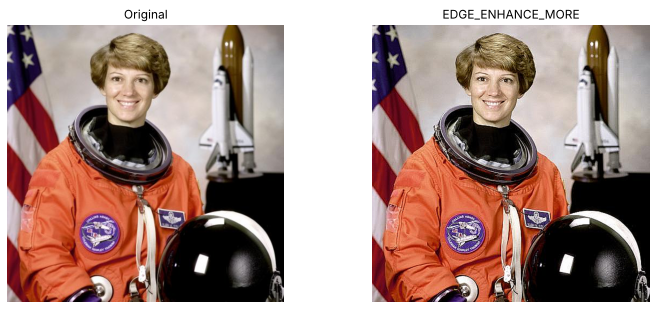

In [ ]:
_ = fotoapp.aplicar_filtro(astronauta, "Edge Enhance More", "3_prueba_nombre_con_espacios.png")

## 4. Boceto: resaltar bordes y contornos

Usamos la foto del **camarógrafo** (una persona con fondo simple: el cielo).
La función prueba 3 técnicas: **Canny**, **Sobel** y **umbral adaptativo**.

Original: (512, 512) -> Instagram: (1080, 1080)


Figura guardada en: resultados/4_boceto_camarografo.png


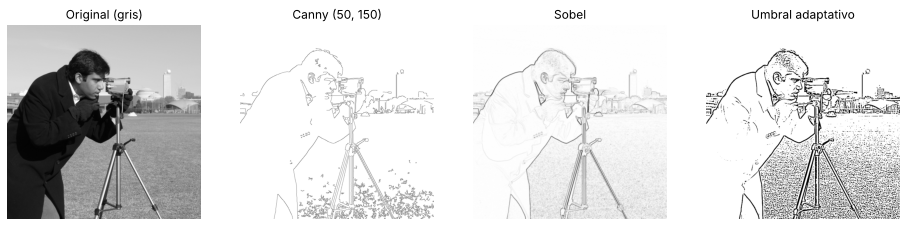

In [ ]:
camarografo = fotoapp.redimensionar_para_red("imagenes/camarografo.png", "Instagram")
dibujo = fotoapp.boceto(camarografo, nombre_archivo="4_boceto_camarografo.png")
dibujo.save("resultados/4_boceto_final.png")

### Ajuste de parámetros de Canny

Canny usa dos umbrales. Con umbrales **bajos** detecta mucho detalle (y ruido, como el pasto); con umbrales **altos** solo quedan los bordes más fuertes.

Figura guardada en: resultados/4_boceto_umbrales_bajos.png


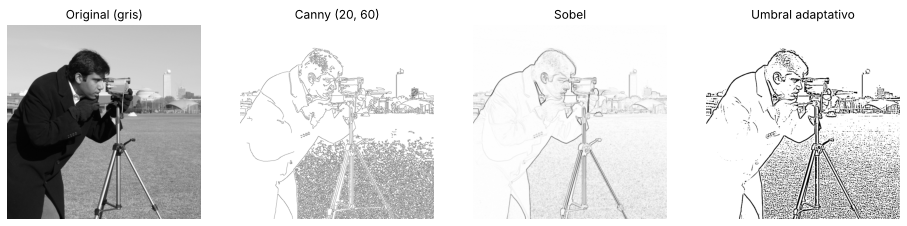

Figura guardada en: resultados/4_boceto_umbrales_altos.png


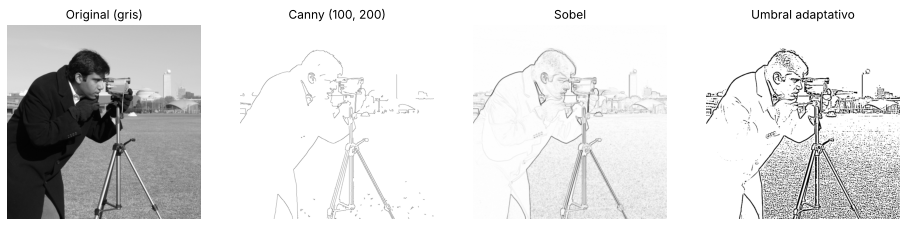

In [ ]:
_ = fotoapp.boceto(camarografo, 20, 60, "4_boceto_umbrales_bajos.png")
_ = fotoapp.boceto(camarografo, 100, 200, "4_boceto_umbrales_altos.png")

**Conclusión:** para un boceto "limpio" nos quedamos con Canny con umbrales medios (50, 150).
Sobel da líneas más gruesas y con grises (no es binario), y el umbral adaptativo marca muy bien las zonas oscuras pero también agrega textura del fondo.

## 5. Menú

El menú es interactivo (usa `input()`), así que conviene probarlo desde la **terminal** de VS Code:

```
python fotoapp.py
```

Si se elige la opción 2, 3 o 4 sin haber pasado antes por la 1, el menú muestra el aviso de `ImagenNoCargadaError` y vuelve a empezar.
Para probarlo desde acá, descomentar la línea de abajo:

In [ ]:
# fotoapp.main()